<a href="https://colab.research.google.com/github/fazalt0614-creator/water_segregation/blob/main/RA2311026050093_CBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cuda


dataset-resized.zip: reconstructing file:   0%|          |  0.00B / 42.8MB            

dataset-resized.zip: downloading bytes:           |  0.00B            

Dataset folder: /content/trashnet/dataset-resized
Total images: 2527
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Split sizes train/val/test: 1768 379 380 | total: 2527
train {'cardboard': 282, 'glass': 350, 'metal': 287, 'paper': 416, 'plastic': 337, 'trash': 96}
val {'cardboard': 61, 'glass': 75, 'metal': 61, 'paper': 89, 'plastic': 72, 'trash': 21}
test {'cardboard': 60, 'glass': 76, 'metal': 62, 'paper': 89, 'plastic': 73, 'trash': 20}


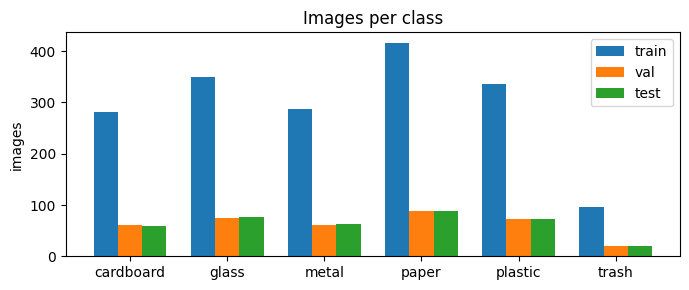

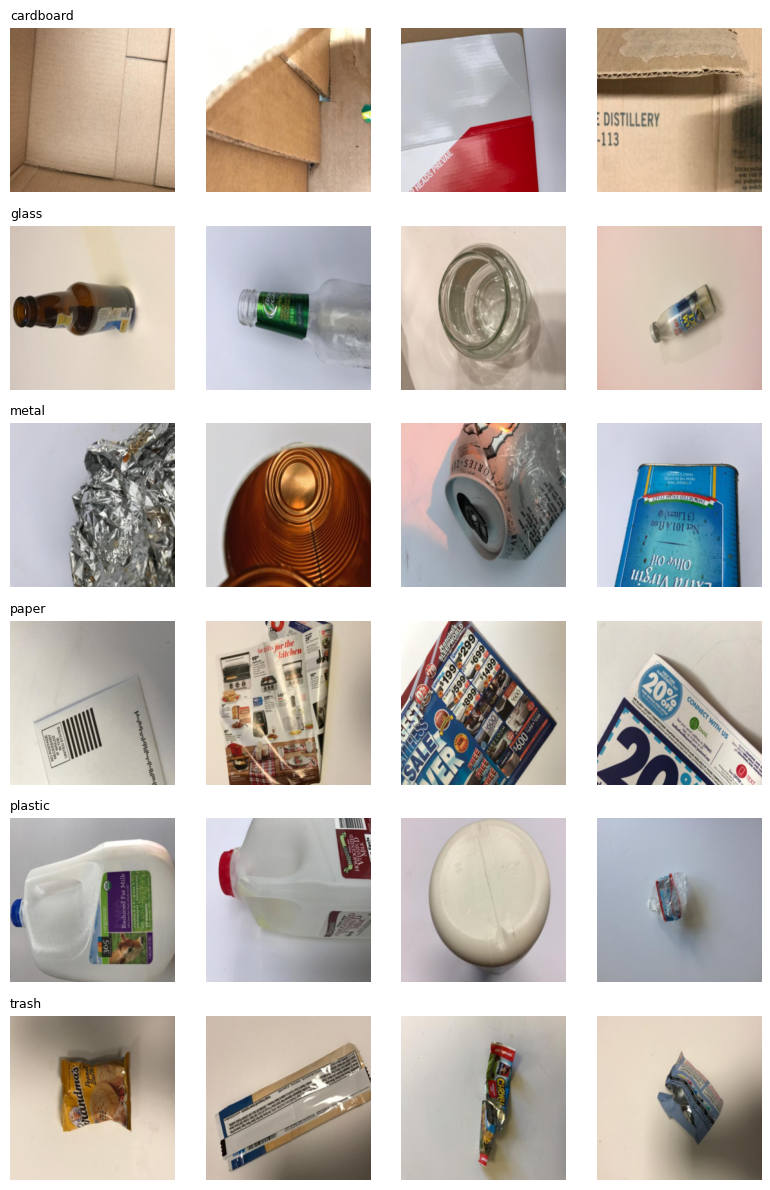

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 158MB/s]


Scratch CNN params: 242310 | EfficientNet-B0 params: 4015234
Train counts: {'cardboard': 282, 'glass': 350, 'metal': 287, 'paper': 416, 'plastic': 337, 'trash': 96}
Class weights: {'cardboard': 1.045, 'glass': 0.842, 'metal': 1.027, 'paper': 0.708, 'plastic': 0.874, 'trash': 3.069}

=== Model A_scratch_CNN_weighted ===
  ep  1 | train loss 1.606 acc 0.374 | val loss 1.345 acc 0.454
  ep  2 | train loss 1.527 acc 0.442 | val loss 1.350 acc 0.454
  ep  3 | train loss 1.478 acc 0.471 | val loss 1.255 acc 0.499
  ep  4 | train loss 1.431 acc 0.493 | val loss 1.278 acc 0.480
  ep  5 | train loss 1.406 acc 0.509 | val loss 1.158 acc 0.507
  ep  6 | train loss 1.391 acc 0.531 | val loss 1.185 acc 0.504
  ep  7 | train loss 1.395 acc 0.532 | val loss 1.079 acc 0.575
  ep  8 | train loss 1.369 acc 0.535 | val loss 1.161 acc 0.562
  ep  9 | train loss 1.337 acc 0.559 | val loss 1.377 acc 0.525
  ep 10 | train loss 1.327 acc 0.572 | val loss 1.055 acc 0.580
  ep 11 | train loss 1.305 acc 0.568 | 

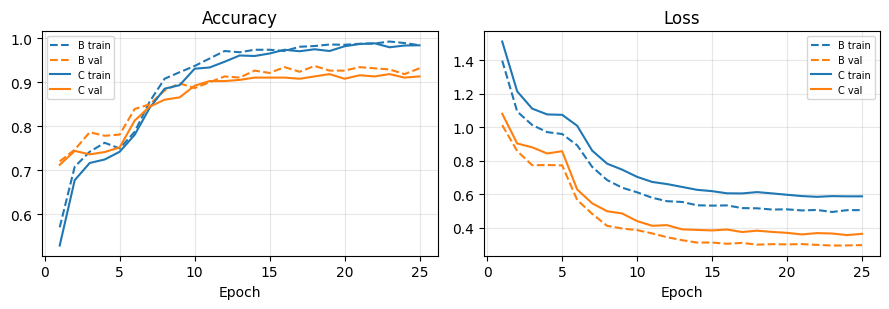

A_scratch_CNN_weighted: test acc 0.6289 | macro F1 0.6229 | trash recall 0.7000
B_EffNetB0_unweighted: test acc 0.9184 | macro F1 0.9126 | trash recall 0.8500
C_EffNetB0_weighted_final: test acc 0.9211 | macro F1 0.9151 | trash recall 0.9500

FINAL MODEL - per-class report (test set)
              precision    recall  f1-score   support

   cardboard     1.0000    0.8833    0.9381        60
       glass     0.9306    0.8816    0.9054        76
       metal     0.9104    0.9839    0.9457        62
       paper     0.9043    0.9551    0.9290        89
     plastic     0.9286    0.8904    0.9091        73
       trash     0.7917    0.9500    0.8636        20

    accuracy                         0.9211       380
   macro avg     0.9109    0.9240    0.9151       380
weighted avg     0.9244    0.9211    0.9212       380



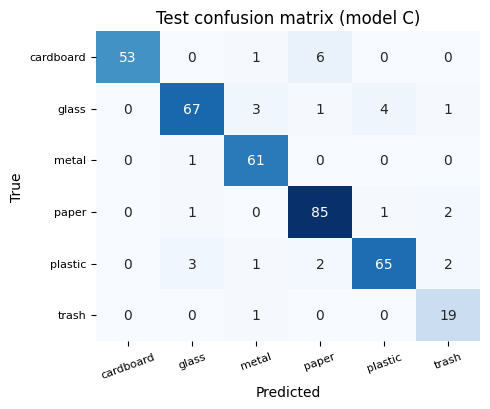

Number of misclassified test images: 30
Confused pairs (true -> predicted): [(('cardboard', 'paper'), 6), (('glass', 'plastic'), 4), (('plastic', 'glass'), 3), (('glass', 'metal'), 3), (('plastic', 'paper'), 2), (('plastic', 'trash'), 2), (('paper', 'trash'), 2), (('plastic', 'metal'), 1), (('paper', 'plastic'), 1), (('cardboard', 'metal'), 1), (('glass', 'trash'), 1), (('metal', 'glass'), 1), (('trash', 'metal'), 1), (('paper', 'glass'), 1), (('glass', 'paper'), 1)]


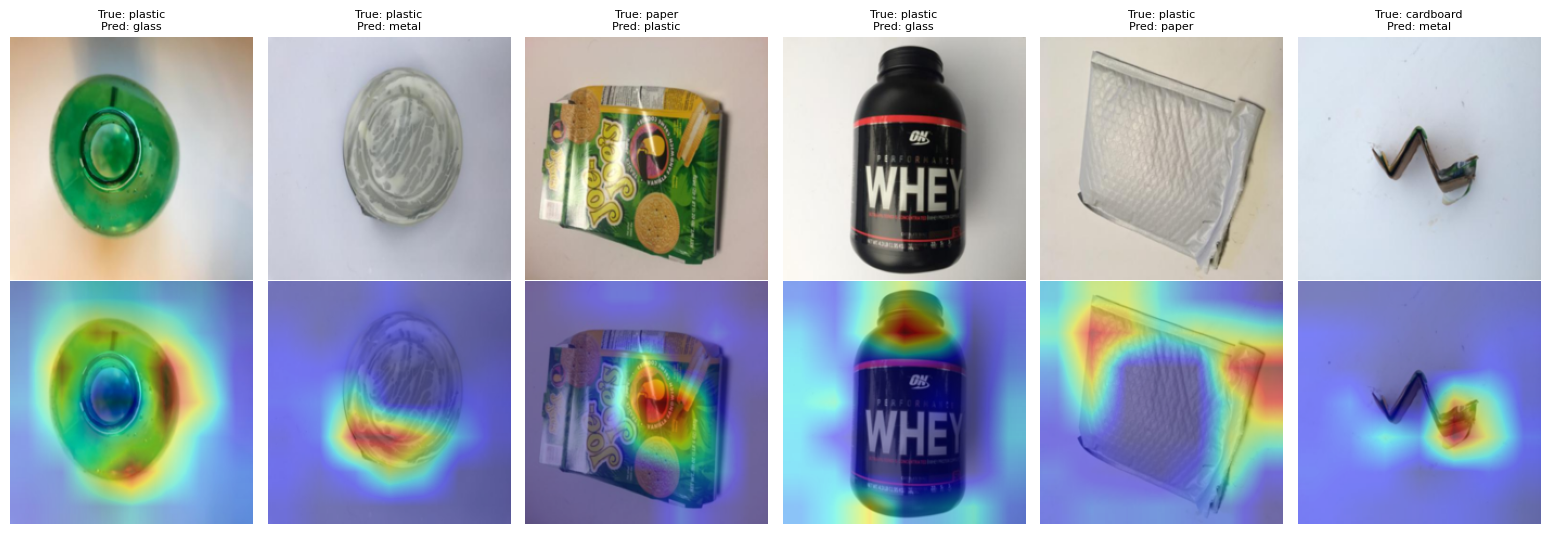

Saved results.json, splits.json, fig_class_counts.png, fig_samples.png, fig_curves.png, fig_cm.png, fig_misclassified.png, efficientnet_b0_trashnet.pth


In [1]:
!pip install -q huggingface_hub

import os, random, json, time, copy, zipfile
import numpy as np, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torchvision
from torchvision import transforms, models
from PIL import Image
from huggingface_hub import hf_hub_download
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score, balanced_accuracy_score

SEED = 42
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device)
RESULTS = {"seed": SEED, "device": str(device), "torch": torch.__version__, "torchvision": torchvision.__version__}

IMG_SRC = 256
IMG = 224

# ---------- 1. Download and unzip TrashNet (resized version) ----------
zpath = hf_hub_download(repo_id="garythung/trashnet", filename="dataset-resized.zip", repo_type="dataset")
with zipfile.ZipFile(zpath) as z: z.extractall("/content/trashnet")
CLASSES = ["cardboard", "glass", "metal", "paper", "plastic", "trash"]
root = None
for dp, dirs, _ in os.walk("/content/trashnet"):
    if set(CLASSES) <= set(dirs) and "__MACOSX" not in dp: root = dp; break
assert root is not None, "Class folders not found after unzip"
print("Dataset folder:", root)
class_names = CLASSES; NC = len(class_names)

paths, labels = [], []
for ci, c in enumerate(class_names):
    for f in sorted(os.listdir(os.path.join(root, c))):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(root, c, f)); labels.append(ci)
paths, labels = np.array(paths), np.array(labels)
print("Total images:", len(labels))

# ---------- 2. Stratified 70/15/15 split with fixed seed ----------
idx = np.arange(len(labels))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=labels[tmp_idx], random_state=SEED)

def load_imgs(ids, size=IMG_SRC):
    return np.stack([np.array(Image.open(paths[i]).convert("RGB").resize((size, size), Image.BILINEAR)) for i in ids])
Xtr, Xva, Xte = load_imgs(tr_idx), load_imgs(va_idx), load_imgs(te_idx)
ytr, yva, yte = labels[tr_idx], labels[va_idx], labels[te_idx]
print("Classes:", class_names)
print("Split sizes train/val/test:", len(ytr), len(yva), len(yte), "| total:", len(ytr)+len(yva)+len(yte))

counts = {n: [int((y == i).sum()) for i in range(NC)] for n, y in [("train", ytr), ("val", yva), ("test", yte)]}
for k, v in counts.items(): print(k, dict(zip(class_names, v)))
RESULTS.update({"class_names": class_names, "split_sizes": {"train": len(ytr), "val": len(yva), "test": len(yte)}, "class_counts": counts})
json.dump({"train": [os.path.basename(paths[i]) for i in tr_idx], "val": [os.path.basename(paths[i]) for i in va_idx],
           "test": [os.path.basename(paths[i]) for i in te_idx]}, open("splits.json", "w"))

fig, ax = plt.subplots(figsize=(7, 3)); w = 0.25
for j, (n, v) in enumerate(counts.items()): ax.bar(np.arange(NC) + j*w, v, w, label=n)
ax.set_xticks(np.arange(NC) + w); ax.set_xticklabels(class_names); ax.set_ylabel("images"); ax.legend(); ax.set_title("Images per class")
plt.tight_layout(); plt.savefig("fig_class_counts.png", dpi=200); plt.show()

fig, axes = plt.subplots(NC, 4, figsize=(8, 2*NC))
for c in range(NC):
    for k, i in enumerate(np.where(ytr == c)[0][:4]):
        axes[c, k].imshow(Xtr[i]); axes[c, k].axis("off")
        if k == 0: axes[c, k].set_title(class_names[c], fontsize=9, loc="left")
plt.tight_layout(); plt.savefig("fig_samples.png", dpi=150); plt.show()

# ---------- 3. Transforms and loaders ----------
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_aug = transforms.Compose([
    transforms.RandomResizedCrop(IMG, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_plain = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class NpDS(torch.utils.data.Dataset):
    def __init__(self, X, y, tf): self.X, self.y, self.tf = X, y, tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(Image.fromarray(self.X[i])), int(self.y[i])

BS = 32
def loader(X, y, tf, shuffle):
    g = torch.Generator(); g.manual_seed(SEED)
    return torch.utils.data.DataLoader(NpDS(X, y, tf), batch_size=BS, shuffle=shuffle, num_workers=2, generator=g)
train_aug = loader(Xtr, ytr, tf_aug, True)
val_loader = loader(Xva, yva, tf_plain, False)
test_loader = loader(Xte, yte, tf_plain, False)

# ---------- 4. Models ----------
def build_scratch():
    def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
    return nn.Sequential(blk(3, 32), blk(32, 64), blk(64, 128), blk(128, 128),
                         nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, NC))

def build_effnet():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier[1] = nn.Linear(1280, NC)
    return m

def n_params(m): return sum(p.numel() for p in m.parameters())
print("Scratch CNN params:", n_params(build_scratch()), "| EfficientNet-B0 params:", n_params(build_effnet()))

# ---------- 5. Imbalance handling: inverse-frequency class weights ----------
cnt = np.bincount(ytr, minlength=NC)
cw = torch.tensor(len(ytr) / (NC * cnt), dtype=torch.float32).to(device)
print("Train counts:", dict(zip(class_names, cnt.tolist())))
print("Class weights:", {c: round(float(x), 3) for c, x in zip(class_names, cw.cpu())})
ce = nn.CrossEntropyLoss()
ce_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)
ce_smooth_w = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.1)

@torch.no_grad()
def evaluate(model, dl):
    model.eval(); loss = correct = n = 0; P, L = [], []
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        out = model(x)
        loss += ce(out, y).item() * len(y); correct += (out.argmax(1) == y).sum().item(); n += len(y)
        P += out.argmax(1).cpu().tolist(); L += y.cpu().tolist()
    return loss/n, correct/n, np.array(P), np.array(L)

def fit(model, train_dl, lr, epochs, patience, hist, criterion, wd=1e-4):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, best_state, bad = 1e9, copy.deepcopy(model.state_dict()), 0
    for ep in range(epochs):
        model.train(); tl = tc = tn = 0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(set_to_none=True)
            out = model(x); loss = criterion(out, y); loss.backward(); opt.step()
            tl += loss.item()*len(y); tc += (out.argmax(1) == y).sum().item(); tn += len(y)
        sched.step()
        vl, va, _, _ = evaluate(model, val_loader)
        hist["train_loss"].append(tl/tn); hist["train_acc"].append(tc/tn); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        print(f"  ep {len(hist['val_loss']):2d} | train loss {tl/tn:.3f} acc {tc/tn:.3f} | val loss {vl:.3f} acc {va:.3f}")
        if vl < best - 1e-4: best, bad, best_state = vl, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= patience: print("  early stopping"); break
    model.load_state_dict(best_state)
    return hist

HP = {"batch_size": BS, "optimizer": "AdamW", "weight_decay": 1e-4, "scheduler": "CosineAnnealing",
      "head_lr": 1e-3, "head_epochs": 5, "finetune_lr": 1e-4, "finetune_max_epochs": 20, "patience": 5,
      "label_smoothing": 0.1, "class_weights": "inverse frequency", "input": IMG, "seed": SEED}
RESULTS["hyperparameters"] = HP

def new_hist(): return {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
trained, hists, times = {}, {}, {}

def run(name, builder, train_dl, criterion, two_stage):
    print("\n=== Model", name, "===")
    seed_all(SEED); m = builder().to(device); h = new_hist(); t0 = time.time()
    if two_stage:
        for p in m.features.parameters(): p.requires_grad = False
        fit(m, train_dl, HP["head_lr"], HP["head_epochs"], 99, h, criterion)
        for p in m.parameters(): p.requires_grad = True
        fit(m, train_dl, HP["finetune_lr"], HP["finetune_max_epochs"], HP["patience"], h, criterion)
    else:
        fit(m, train_dl, 1e-3, 40, HP["patience"], h, criterion)
    times[name] = time.time() - t0; trained[name] = m; hists[name] = h
    print(f"  training time {times[name]:.0f}s, epochs run {len(h['val_loss'])}")

# A: scratch CNN + weighted loss | B: EffNet, no class weights | C: EffNet + class weights (final)
run("A_scratch_CNN_weighted", build_scratch, train_aug, ce_smooth_w, two_stage=False)
run("B_EffNetB0_unweighted", build_effnet, train_aug, ce_smooth, two_stage=True)
run("C_EffNetB0_weighted_final", build_effnet, train_aug, ce_smooth_w, two_stage=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for name, ls in [("B_EffNetB0_unweighted", "--"), ("C_EffNetB0_weighted_final", "-")]:
    h = hists[name]; e = range(1, len(h["val_loss"]) + 1)
    axes[0].plot(e, h["train_acc"], ls, color="C0", label=f"{name[:1]} train"); axes[0].plot(e, h["val_acc"], ls, color="C1", label=f"{name[:1]} val")
    axes[1].plot(e, h["train_loss"], ls, color="C0", label=f"{name[:1]} train"); axes[1].plot(e, h["val_loss"], ls, color="C1", label=f"{name[:1]} val")
axes[0].set_title("Accuracy"); axes[1].set_title("Loss")
for a in axes: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("fig_curves.png", dpi=200); plt.show()

# ---------- 6. Test-set evaluation (once) ----------
final = "C_EffNetB0_weighted_final"
RESULTS["final_model"] = final; RESULTS["models"] = {}
preds = {}
for name, m in trained.items():
    tl, ta, P, L = evaluate(m, test_loader); preds[name] = (P, L)
    rep = classification_report(L, P, labels=list(range(NC)), target_names=class_names, output_dict=True, zero_division=0)
    h = hists[name]
    RESULTS["models"][name] = {
        "params": n_params(m), "test_acc": float(accuracy_score(L, P)), "macro_f1": float(f1_score(L, P, average="macro")),
        "balanced_acc": float(balanced_accuracy_score(L, P)),
        "test_loss": tl, "train_time_s": times[name], "epochs_run": len(h["val_loss"]),
        "final_train_acc": h["train_acc"][-1], "best_val_acc": max(h["val_acc"]),
        "per_class": {c: {k: float(rep[c][k]) for k in ("precision", "recall", "f1-score", "support")} for c in class_names}}
    r = RESULTS["models"][name]
    print(f"{name}: test acc {ta:.4f} | macro F1 {r['macro_f1']:.4f} | trash recall {r['per_class']['trash']['recall']:.4f}")

P, L = preds[final]
print("\nFINAL MODEL - per-class report (test set)")
print(classification_report(L, P, target_names=class_names, digits=4))

cm = confusion_matrix(L, P, labels=list(range(NC)))
plt.figure(figsize=(5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix (model C)")
plt.xticks(rotation=20, fontsize=8); plt.yticks(rotation=0, fontsize=8)
plt.tight_layout(); plt.savefig("fig_cm.png", dpi=200); plt.show()
RESULTS["confusion_matrix"] = cm.tolist()

# ---------- 7. Grad-CAM on misclassified images ----------
def gradcam(model, x, target):
    feats, grads = {}, {}
    layer = model.features[-1]
    h1 = layer.register_forward_hook(lambda m, i, o: feats.update(a=o))
    h2 = layer.register_full_backward_hook(lambda m, gi, go: grads.update(g=go[0]))
    model.eval(); out = model(x); model.zero_grad(); out[0, target].backward()
    h1.remove(); h2.remove()
    w = grads["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats["a"]).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(IMG, IMG), mode="bilinear")[0, 0]
    return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

m = trained[final]
wrong = np.where(P != L)[0]
print("Number of misclassified test images:", len(wrong))
pairs = {}
for i in wrong: pairs[(class_names[L[i]], class_names[P[i]])] = pairs.get((class_names[L[i]], class_names[P[i]]), 0) + 1
print("Confused pairs (true -> predicted):", sorted(pairs.items(), key=lambda kv: -kv[1]))
RESULTS["confused_pairs"] = {f"{a}->{b}": n for (a, b), n in pairs.items()}
show = wrong[:6]
if len(show):
    fig, axes = plt.subplots(2, len(show), figsize=(2.6*len(show), 5.4), squeeze=False)
    for k, i in enumerate(show):
        img = Xte[i]; x = tf_plain(Image.fromarray(img)).unsqueeze(0).to(device)
        cam = gradcam(m, x, int(P[i]))
        axes[0, k].imshow(Image.fromarray(img).resize((IMG, IMG))); axes[0, k].axis("off")
        axes[0, k].set_title(f"True: {class_names[L[i]]}\nPred: {class_names[P[i]]}", fontsize=8)
        axes[1, k].imshow(Image.fromarray(img).resize((IMG, IMG))); axes[1, k].imshow(cam, cmap="jet", alpha=0.45); axes[1, k].axis("off")
    plt.tight_layout(); plt.savefig("fig_misclassified.png", dpi=150); plt.show()

torch.save({"model_state_dict": trained[final].state_dict(), "class_names": class_names, "hyperparameters": HP}, "efficientnet_b0_trashnet.pth")
with open("results.json", "w") as f: json.dump(RESULTS, f, indent=2)
print("Saved results.json, splits.json, fig_class_counts.png, fig_samples.png, fig_curves.png, fig_cm.png, fig_misclassified.png, efficientnet_b0_trashnet.pth")

In [2]:
import os, zipfile
from google.colab import files

OUT = [
    "results.json", "splits.json",
    "fig_class_counts.png", "fig_samples.png", "fig_curves.png",
    "fig_cm.png", "fig_misclassified.png",
    "efficientnet_b0_trashnet.pth",
]

zip_name = "PS31_results.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT:
        if os.path.exists(f):
            z.write(f); print("added  ", f)
        else:
            print("MISSING", f)

print("Zip size: %.1f MB" % (os.path.getsize(zip_name) / 1e6))
files.download(zip_name)

added   results.json
added   splits.json
added   fig_class_counts.png
added   fig_samples.png
added   fig_curves.png
added   fig_cm.png
added   fig_misclassified.png
added   efficientnet_b0_trashnet.pth
Zip size: 18.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>